# DCGAN — Unsupervised Representation Learning with Deep Convolutional GANs

**Paper:** Radford, Metz, & Chintala (2015), *Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks*, arXiv:1511.06434

This notebook implements a DCGAN with convolutional generator and discriminator architectures
following the paper's architectural guidelines (strided convolutions, batch normalization,
no pooling, ReLU in generator, LeakyReLU in discriminator), trains on CIFAR-10 (resized to 64×64),
and visualizes the latent-space walk (interpolation between random points in Z-space).

## 1. Setup & Imports

In [1]:
import atexit
import contextlib
import io
import json
import os
import shutil
import time

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Set random seeds for reproducibility
manualSeed = 42
torch.manual_seed(manualSeed)
np.random.seed(manualSeed)
torch.use_deterministic_algorithms(False)

# On Kaggle, keep a copy of this notebook with its outputs when the kernel exits,
# so `kaggle kernels output` can download the executed version
KAGGLE_NB = '/kaggle/working/__notebook__.ipynb'
if os.path.isdir('/kaggle/working'):
    atexit.register(lambda: os.path.exists(KAGGLE_NB) and shutil.copy(KAGGLE_NB, '/kaggle/working/executed_solution.ipynb'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'PyTorch version: {torch.__version__}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')


Device: cuda
PyTorch version: 2.10.0+cu128
GPU: Tesla T4


## 2. Hyperparameters

Following the paper's training configuration: Adam optimizer with lr=0.0002 and beta1=0.5,
batch size 128, 100-dim noise vector, weights initialized from N(0, 0.02).
We use 15 epochs on 50K CIFAR-10 images (390 batches × 15 = 5,850 iterations). That is far fewer
iterations than the paper (5 epochs on 3M LSUN images ≈ 117K iterations), to fit Kaggle's time limit.
The generator width matches the paper: 1024 channels at 4×4, halving at each upsampling step.

In [2]:
latent_dim = 100        # Dimension of noise vector z (uniform prior)
img_channels = 3        # RGB images
img_size = 64           # Image spatial size (paper generates 64x64)
feature_maps_g = 128    # Base feature maps for generator (×8 = 1024 channels at 4×4, as in the paper)
feature_maps_d = 64     # Base feature maps for discriminator
lr = 0.0002             # Learning rate (paper found 0.001 too high)
beta1 = 0.5             # Adam beta1 (paper reduced from 0.9 to 0.5 for stability)
batch_size = 128        # Minibatch size (as in the paper)
num_epochs = 15         # Training epochs (tuned for GPU time limits)
leak_slope = 0.2        # LeakyReLU negative slope (as in the paper)

print(f'Latent dim: {latent_dim}')
print(f'Image size: {img_size}x{img_size}')
print(f'Learning rate: {lr}, beta1: {beta1}')
print(f'Batch size: {batch_size}, Epochs: {num_epochs}')


Latent dim: 100
Image size: 64x64
Learning rate: 0.0002, beta1: 0.5
Batch size: 128, Epochs: 15


## 3. Data Loading (CIFAR-10, resized to 64×64)

Load CIFAR-10 via torchvision, resize to 64×64, and normalize to [-1, 1]
to match the Tanh activation output range of the generator.

The paper trained on LSUN bedrooms (3M images), ImageNet-1k, and a custom Faces dataset.
We use CIFAR-10 for accessibility — it's a standard benchmark with diverse natural images.

In [3]:
transform = transforms.Compose([
    transforms.Resize(img_size),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))  # Scale to [-1, 1]
])

# On Kaggle, attach the dataset pankrzysiu/cifar10-python to skip the slow download;
# anywhere else torchvision downloads CIFAR-10 into ./data
KAGGLE_CIFAR = '/kaggle/input/cifar10-python'
CIFAR_ROOT = KAGGLE_CIFAR if os.path.isdir(KAGGLE_CIFAR + '/cifar-10-batches-py') else './data'

# a fresh download prints a progress bar; silence it
with contextlib.redirect_stderr(io.StringIO()):
    dataset = torchvision.datasets.CIFAR10(root=CIFAR_ROOT, train=True, download=True, transform=transform)
print(f'CIFAR-10 root: {CIFAR_ROOT}')
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True, num_workers=2)

print(f'Dataset: CIFAR-10 (train), {len(dataset)} images')
print(f'Batches per epoch: {len(dataloader)}')

# Show a sample batch
sample_batch = next(iter(dataloader))
print(f'Batch shape: {sample_batch[0].shape}')
print(f'Pixel range: [{sample_batch[0].min():.2f}, {sample_batch[0].max():.2f}]')


CIFAR-10 root: /kaggle/input/cifar10-python
Dataset: CIFAR-10 (train), 50000 images
Batches per epoch: 390


Batch shape: torch.Size([128, 3, 64, 64])
Pixel range: [-1.00, 1.00]


## 4. Generator Network (G)

Maps a 100-dim noise vector z to a 64×64×3 RGB image using transposed convolutions.

DCGAN architectural guidelines:
- All convolutional (transposed conv for upsampling), no pooling
- BatchNorm in all layers
- ReLU activation in all layers except output (Tanh)
- First layer is a fully-connected projection reshaped to a 4D tensor
- No fully-connected hidden layers

In [4]:
class Generator(nn.Module):
    def __init__(self, latent_dim, img_channels, feature_maps):
        super(Generator, self).__init__()
        self.net = nn.Sequential(
            # Input: (latent_dim, 1, 1) -> (feature_maps*8, 4, 4)
            nn.ConvTranspose2d(latent_dim, feature_maps * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(feature_maps * 8),
            nn.ReLU(True),
            # State: (feature_maps*8, 4, 4) -> (feature_maps*4, 8, 8)
            nn.ConvTranspose2d(feature_maps * 8, feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 4),
            nn.ReLU(True),
            # State: (feature_maps*4, 8, 8) -> (feature_maps*2, 16, 16)
            nn.ConvTranspose2d(feature_maps * 4, feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(True),
            # State: (feature_maps*2, 16, 16) -> (feature_maps, 32, 32)
            nn.ConvTranspose2d(feature_maps * 2, feature_maps, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(True),
            # State: (feature_maps, 32, 32) -> (img_channels, 64, 64)
            nn.ConvTranspose2d(feature_maps, img_channels, 4, 2, 1, bias=False),
            nn.Tanh()  # Output in [-1, 1]
        )

    def forward(self, z):
        # z: (batch, latent_dim, 1, 1) -> (batch, 3, 64, 64)
        return self.net(z)

G = Generator(latent_dim, img_channels, feature_maps_g).to(device)
print(G)
print(f'Total parameters: {sum(p.numel() for p in G.parameters()):,}')


Generator(
  (net): Sequential(
    (0): ConvTranspose2d(100, 1024, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(1024, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(128, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (13): Tanh()
 

## 5. Discriminator Network (D)

Classifies 64×64×3 image as real (1) or fake (0) using strided convolutions.

DCGAN architectural guidelines:
- All convolutional (strided conv for downsampling), no pooling
- BatchNorm in all layers EXCEPT the input layer (paper: applying BN to D input caused instability)
- LeakyReLU activation (slope=0.2) in all layers
- No fully-connected hidden layers
- Last conv outputs 1×1, then sigmoid for probability

In [5]:
class Discriminator(nn.Module):
    def __init__(self, img_channels, feature_maps):
        super(Discriminator, self).__init__()
        self.net = nn.Sequential(
            # Input: (img_channels, 64, 64) -> (feature_maps, 32, 32)
            nn.Conv2d(img_channels, feature_maps, 4, 2, 1, bias=False),
            nn.LeakyReLU(leak_slope, inplace=True),
            # No BatchNorm on first layer (paper guideline)
            # State: (feature_maps, 32, 32) -> (feature_maps*2, 16, 16)
            nn.Conv2d(feature_maps, feature_maps * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(leak_slope, inplace=True),
            # State: (feature_maps*2, 16, 16) -> (feature_maps*4, 8, 8)
            nn.Conv2d(feature_maps * 2, feature_maps * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 4),
            nn.LeakyReLU(leak_slope, inplace=True),
            # State: (feature_maps*4, 8, 8) -> (feature_maps*8, 4, 4)
            nn.Conv2d(feature_maps * 4, feature_maps * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feature_maps * 8),
            nn.LeakyReLU(leak_slope, inplace=True),
            # State: (feature_maps*8, 4, 4) -> (1, 1, 1)
            nn.Conv2d(feature_maps * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        # x: (batch, 3, 64, 64) -> (batch, 1, 1, 1)
        return self.net(x)

D = Discriminator(img_channels, feature_maps_d).to(device)
print(D)
print(f'Total parameters: {sum(p.numel() for p in D.parameters()):,}')


Discriminator(
  (net): Sequential(
    (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (12): Sigmoid()
  )
)
Total parameters: 2,765,568


## 6. Weight Initialization

The paper specifies: all weights initialized from a zero-centered Normal distribution
with standard deviation 0.02. BatchNorm weights initialized to N(1.0, 0.02) with bias = 0.

In [6]:
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

G.apply(weights_init)
D.apply(weights_init)
print('Weights initialized: Conv -> N(0, 0.02), BatchNorm weight -> N(1, 0.02), bias -> 0')

# Verify init
conv_w = list(G.net[0].parameters())[0]
print(f'Generator first conv weight: mean={conv_w.mean().item():.4f}, std={conv_w.std().item():.4f}')


Weights initialized: Conv -> N(0, 0.02), BatchNorm weight -> N(1, 0.02), bias -> 0
Generator first conv weight: mean=-0.0000, std=0.0200


## 7. Loss Function & Optimizers

### Adversarial Loss (BCE)

The GAN objective is:
```
min_G max_D V(D,G) = E[log D(x)] + E[log(1 - D(G(z)))]
```

- **D loss**: BCE(D(real), 1) + BCE(D(fake), 0) — D wants to correctly classify
- **G loss**: BCE(D(fake), 1) — non-saturating: G wants to fool D (uses real labels for fake)

Both optimizers use Adam with lr=0.0002, beta1=0.5 (paper's tuned hyperparameters).

In [7]:
criterion = nn.BCELoss()

optimizer_G = optim.Adam(G.parameters(), lr=lr, betas=(beta1, 0.999))
optimizer_D = optim.Adam(D.parameters(), lr=lr, betas=(beta1, 0.999))

real_label = 1.0
fake_label = 0.0

print('Loss: BCELoss')
print(f'Optimizer G: Adam (lr={lr}, beta1={beta1})')
print(f'Optimizer D: Adam (lr={lr}, beta1={beta1})')


Loss: BCELoss
Optimizer G: Adam (lr=0.0002, beta1=0.5)
Optimizer D: Adam (lr=0.0002, beta1=0.5)


## 8. Training Loop

Standard adversarial training:
1. Update D: classify real (label=1) and fake (label=0), maximize BCE
2. Update G: generate fake, classify with D, use real labels (non-saturating loss)

We save generated samples from a fixed noise vector at regular intervals to track progress.

In [8]:
fixed_noise = torch.randn(64, latent_dim, 1, 1, device=device)

img_list = []
G_losses = []
D_losses = []

train_start = time.time()
print('Starting DCGAN training...')
print(f'Epochs: {num_epochs}, Batch size: {batch_size}')
print('-' * 60)

for epoch in range(num_epochs):
    for i, (real_imgs, _) in enumerate(dataloader):
        real_imgs = real_imgs.to(device)
        batch_size_cur = real_imgs.size(0)

        # --- Train Discriminator ---
        D.zero_grad()
        # Real batch
        label_real = torch.full((batch_size_cur,), real_label, device=device)
        output_real = D(real_imgs).view(-1)
        loss_D_real = criterion(output_real, label_real)
        loss_D_real.backward()
        # Fake batch
        noise = torch.randn(batch_size_cur, latent_dim, 1, 1, device=device)
        fake_imgs = G(noise)
        label_fake = torch.full((batch_size_cur,), fake_label, device=device)
        output_fake = D(fake_imgs.detach()).view(-1)
        loss_D_fake = criterion(output_fake, label_fake)
        loss_D_fake.backward()
        # Update D
        loss_D = loss_D_real + loss_D_fake
        optimizer_D.step()

        # --- Train Generator ---
        G.zero_grad()
        # Non-saturating loss: use real labels for fake samples
        label_g = torch.full((batch_size_cur,), real_label, device=device)
        output_g = D(fake_imgs).view(-1)
        loss_G = criterion(output_g, label_g)
        loss_G.backward()
        optimizer_G.step()

        # Record losses
        G_losses.append(loss_G.item())
        D_losses.append(loss_D.item())

    # Print progress
    if (epoch + 1) % 3 == 0 or epoch == 0:
        print(f'[{epoch+1:3d}/{num_epochs}] Loss_D: {loss_D.item():.4f} Loss_G: {loss_G.item():.4f} '
              f'D(x): {output_real.mean().item():.3f} D(G(z)): {output_g.mean().item():.3f}')

    # Save generated samples from fixed noise every 3 epochs
    if (epoch + 1) % 3 == 0 or epoch == 0:
        with torch.no_grad():
            fake = G(fixed_noise).detach().cpu()
        img_list.append(fake)

train_seconds = time.time() - train_start
print('-' * 60)
print(f'Training complete! {len(G_losses):,} iterations in {train_seconds/60:.1f} min')

# Save the run's key numbers next to the figures
results = {
    'epochs': num_epochs, 'iterations': len(G_losses), 'train_seconds': round(train_seconds, 1),
    'generator_params': sum(p.numel() for p in G.parameters()),
    'discriminator_params': sum(p.numel() for p in D.parameters()),
    'final_loss_D': loss_D.item(), 'final_loss_G': loss_G.item(),
    'final_D_x': output_real.mean().item(), 'final_D_G_z': output_g.mean().item(),
    'mean_loss_D_last_epoch': float(np.mean(D_losses[-len(dataloader):])),
    'mean_loss_G_last_epoch': float(np.mean(G_losses[-len(dataloader):])),
}
with open('dcgan_results.json', 'w') as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

Starting DCGAN training...
Epochs: 15, Batch size: 128
------------------------------------------------------------


[  1/15] Loss_D: 0.1790 Loss_G: 6.8471 D(x): 0.915 D(G(z)): 0.002


[  3/15] Loss_D: 0.4482 Loss_G: 2.9631 D(x): 0.769 D(G(z)): 0.073


[  6/15] Loss_D: 0.5021 Loss_G: 2.0966 D(x): 0.773 D(G(z)): 0.150


[  9/15] Loss_D: 0.8279 Loss_G: 1.3873 D(x): 0.513 D(G(z)): 0.279


[ 12/15] Loss_D: 0.5849 Loss_G: 4.9282 D(x): 0.938 D(G(z)): 0.011


[ 15/15] Loss_D: 0.7480 Loss_G: 2.5802 D(x): 0.660 D(G(z)): 0.094
------------------------------------------------------------
Training complete! 5,850 iterations in 25.9 min
{
  "epochs": 15,
  "iterations": 5850,
  "train_seconds": 1555.6,
  "generator_params": 12658432,
  "discriminator_params": 2765568,
  "final_loss_D": 0.7479846477508545,
  "final_loss_G": 2.580242156982422,
  "final_D_x": 0.659822404384613,
  "final_D_G_z": 0.09386520832777023,
  "mean_loss_D_last_epoch": 0.8071273831841655,
  "mean_loss_G_last_epoch": 2.786259790853812
}


## 9. Loss Curves

Visualize the adversarial loss dynamics. D and G losses oscillate as they compete rather than
settling to a fixed value. At the theoretical equilibrium (D outputs 0.5 everywhere) G's loss would be
log(2) ≈ 0.69 and D's loss, the sum of a real and a fake BCE term, 2·log(2) ≈ 1.39; the dashed line marks log(2).
In practice neither loss converges to these values in a short run.

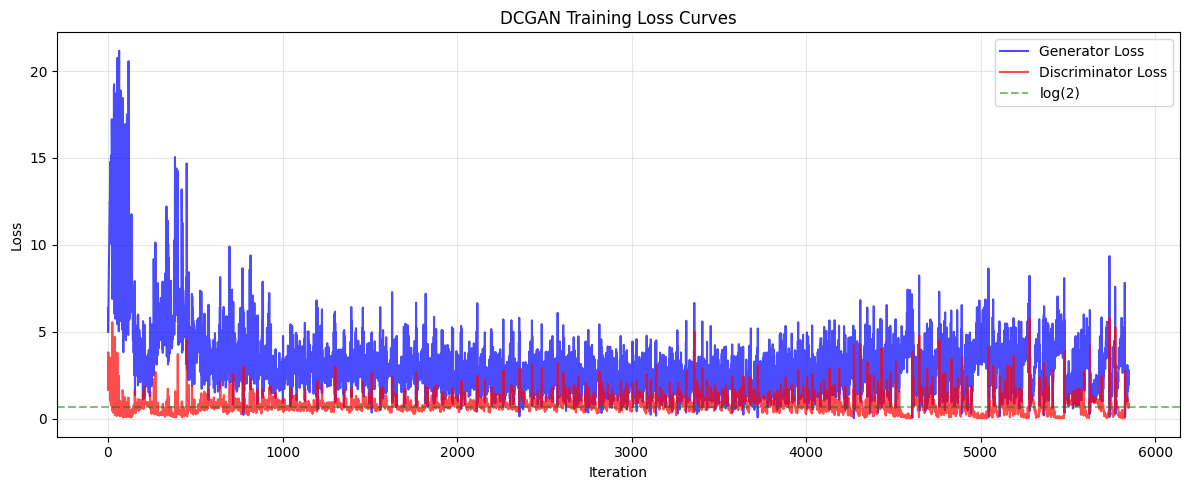

In [9]:
plt.figure(figsize=(12, 5))
plt.plot(G_losses, label='Generator Loss', alpha=0.7, color='blue')
plt.plot(D_losses, label='Discriminator Loss', alpha=0.7, color='red')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('DCGAN Training Loss Curves')
plt.axhline(y=np.log(2), color='green', linestyle='--', alpha=0.5, label='log(2)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('dcgan_loss_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 10. Generated Samples Over Training

Show generated images at different training stages from the fixed noise vector
to visualize progressive improvement.

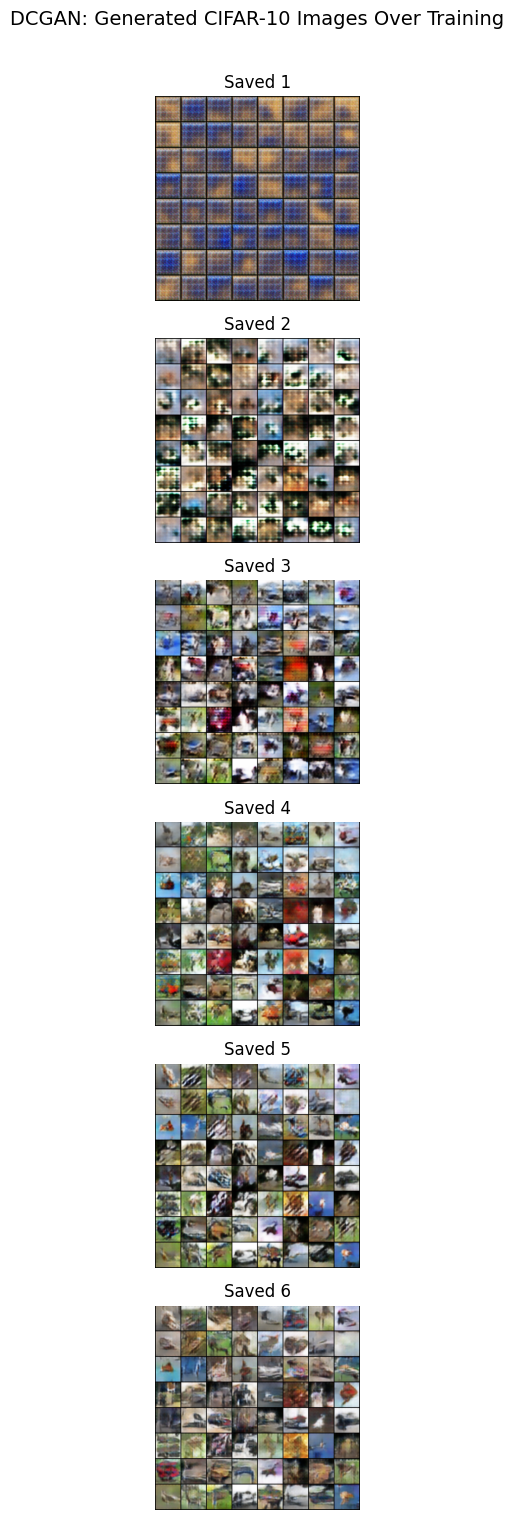

In [10]:
stages = list(range(len(img_list)))
stage_names = [f'Saved {i+1}' for i in range(len(img_list))]

fig, axes = plt.subplots(len(stages), 1, figsize=(10, 2.5*len(stages)))
if len(stages) == 1:
    axes = [axes]
for row, (stage, name) in enumerate(zip(stages, stage_names)):
    img_grid = torchvision.utils.make_grid(img_list[stage][:64], nrow=8, normalize=True, padding=2)
    axes[row].imshow(img_grid.numpy().transpose(1, 2, 0))
    axes[row].set_title(name, fontsize=12)
    axes[row].axis('off')
plt.suptitle('DCGAN: Generated CIFAR-10 Images Over Training', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('dcgan_training_progress.png', dpi=150, bbox_inches='tight')
plt.show()


## 11. Real vs Fake Comparison

Side-by-side comparison of real CIFAR-10 images and generated images after full training.

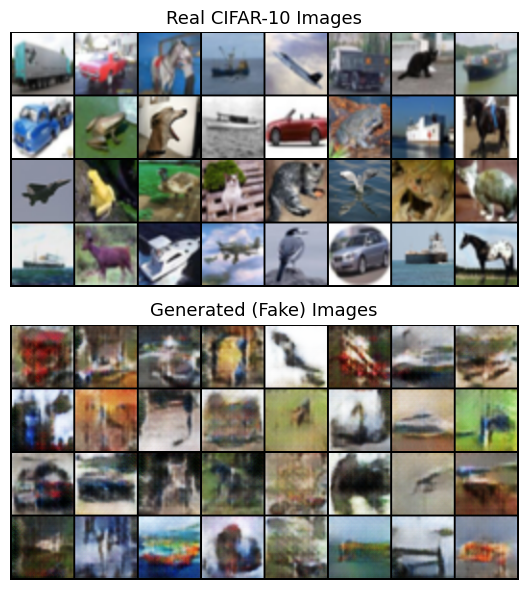

In [11]:
real_batch = next(iter(dataloader))
real_imgs_show = real_batch[0][:32].to(device)

with torch.no_grad():
    fake_imgs_show = G(torch.randn(32, latent_dim, 1, 1, device=device)).detach()

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

real_grid = torchvision.utils.make_grid(real_imgs_show, nrow=8, normalize=True, padding=2)
axes[0].imshow(real_grid.cpu().numpy().transpose(1, 2, 0))
axes[0].set_title('Real CIFAR-10 Images', fontsize=13)
axes[0].axis('off')

fake_grid = torchvision.utils.make_grid(fake_imgs_show, nrow=8, normalize=True, padding=2)
axes[1].imshow(fake_grid.cpu().numpy().transpose(1, 2, 0))
axes[1].set_title('Generated (Fake) Images', fontsize=13)
axes[1].axis('off')

plt.tight_layout()
plt.savefig('dcgan_real_vs_fake.png', dpi=150, bbox_inches='tight')
plt.show()


## 12. Latent Space Walk (Interpolation)

The paper (Section 6.1) walks the latent space of its LSUN bedroom model and finds smooth,
semantically meaningful transitions (e.g. a window slowly appearing), with no sharp jumps
that would suggest memorization. We linearly interpolate between two random points in Z-space
and generate an image at each step to see how our much shorter CIFAR-10 run behaves.

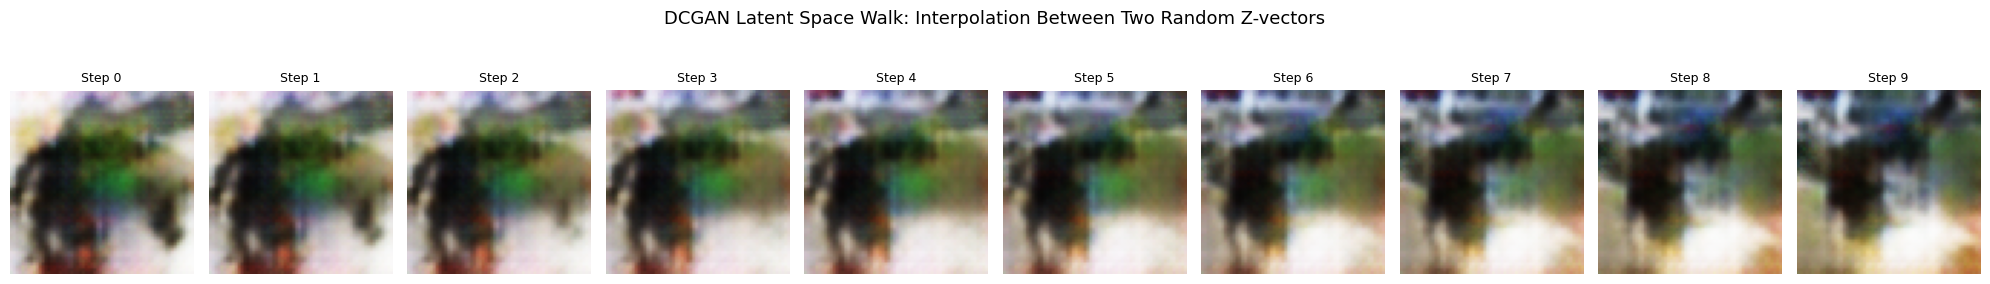

In [12]:
num_steps = 10

z_start = torch.randn(1, latent_dim, 1, 1, device=device)
z_end = torch.randn(1, latent_dim, 1, 1, device=device)

interpolated = []
with torch.no_grad():
    for i in range(num_steps):
        alpha = i / (num_steps - 1)
        z_interp = (1 - alpha) * z_start + alpha * z_end
        img = G(z_interp).cpu()
        interpolated.append(img)

interpolated = torch.cat(interpolated, dim=0)

fig, axes = plt.subplots(1, num_steps, figsize=(20, 3))
for i in range(num_steps):
    img = interpolated[i] * 0.5 + 0.5  # Denormalize [-1,1] -> [0,1]
    img = img.clamp(0, 1)
    axes[i].imshow(img.numpy().transpose(1, 2, 0))
    axes[i].set_title(f'Step {i}', fontsize=9)
    axes[i].axis('off')
plt.suptitle('DCGAN Latent Space Walk: Interpolation Between Two Random Z-vectors', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('dcgan_latent_walk.png', dpi=150, bbox_inches='tight')
plt.show()



## 13. Latent Space Vector Arithmetic

The paper showed that averaging Z-vectors for multiple samples per concept enables
arithmetic: e.g., `mean(Z_A) - mean(Z_B) + mean(Z_C) ≈ concept combining A-B+C`.

We demonstrate with random samples: averaging multiple noise vectors produces a
more stable, representative generation (the paper found single-sample arithmetic
was unstable, but averaging 3+ samples was consistent).

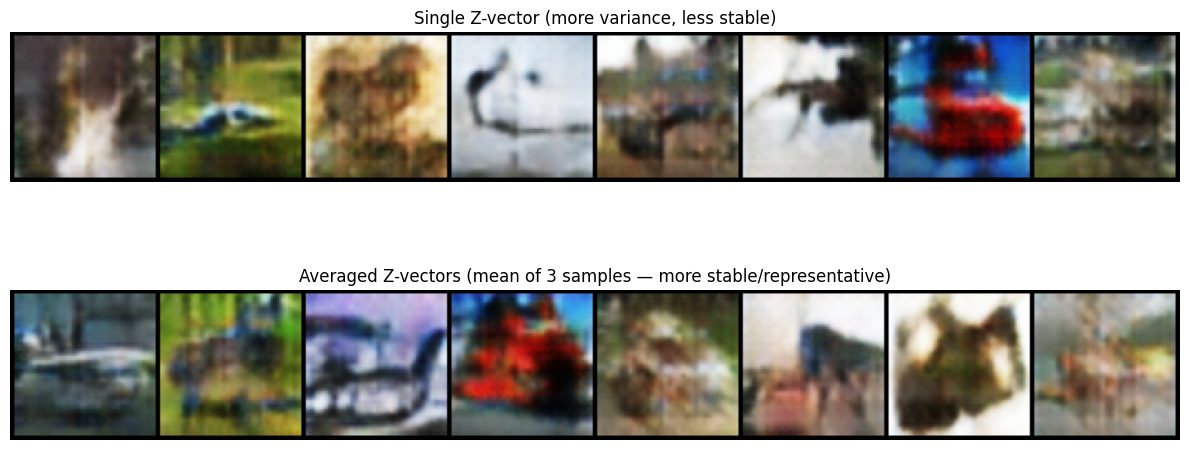

The paper found that averaging 3+ Z-vectors per concept produces more stable,
representative generations — enabling consistent vector arithmetic.


In [13]:
# Demonstrate averaging effect: generate with averaged noise vs single noise
n_avg = 3

with torch.no_grad():
    # Single noise vectors
    single_z = torch.randn(8, latent_dim, 1, 1, device=device)
    single_imgs = G(single_z).cpu()

    # Averaged noise vectors (average of n_avg random samples each)
    avg_z = torch.randn(8, n_avg, latent_dim, 1, 1, device=device).mean(dim=1)
    avg_imgs = G(avg_z).cpu()

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

single_grid = torchvision.utils.make_grid(single_imgs, nrow=8, normalize=True, padding=2)
axes[0].imshow(single_grid.numpy().transpose(1, 2, 0))
axes[0].set_title('Single Z-vector (more variance, less stable)', fontsize=12)
axes[0].axis('off')

avg_grid = torchvision.utils.make_grid(avg_imgs, nrow=8, normalize=True, padding=2)
axes[1].imshow(avg_grid.numpy().transpose(1, 2, 0))
axes[1].set_title(f'Averaged Z-vectors (mean of {n_avg} samples — more stable/representative)', fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.savefig('dcgan_latent_arithmetic.png', dpi=150, bbox_inches='tight')
plt.show()

print('The paper found that averaging 3+ Z-vectors per concept produces more stable,')
print('representative generations — enabling consistent vector arithmetic.')


## 14. Summary

### What the run above shows
- **Run:** 15 epochs, 5,850 iterations, 25.9 minutes on a Tesla T4. Generator 12,658,432 parameters, discriminator 2,765,568.
- **Losses oscillate and do not converge.** Loss_G spikes to about 20 in the first ~150 iterations while D wins easily, then swings between roughly 1 and 6; Loss_D stays mostly between 0.1 and 1.5. Averaged over the last epoch, Loss_D is 0.81 and Loss_G 2.79 (last batch: 0.75 and 2.58, D(x) = 0.66, D(G(z)) = 0.09). Between about iterations 4,600 and 5,600, Loss_D repeatedly drops close to 0 while Loss_G spikes: the discriminator temporarily wins, the kind of remaining instability the paper itself acknowledges.
- **Samples are blurry.** The generated images have CIFAR-like colours and layouts (sky, water and ground, vehicle- and animal-like shapes), with a faint grid-like texture in places, but no recognisable objects. They are varied, with no sign of mode collapse.
- **The latent walk is gradual:** over the ten steps the dark foreground shape shrinks and the background shifts from white and green to brown and orange, with no sudden jumps.
- **Takeaway:** the DCGAN guidelines give a convolutional GAN that trains without collapsing on a short budget, but paper-quality samples need far more training (about 117K iterations on 3M LSUN images in the paper, versus 5,850 here).

### What we built
- A **convolutional generator** (ConvTranspose2d + BatchNorm + ReLU + Tanh) that maps 100-dim noise → 64×64 RGB images
- A **convolutional discriminator** (Conv2d + BatchNorm + LeakyReLU + Sigmoid) that classifies images as real/fake
- The **DCGAN architectural guidelines**: strided convolutions (no pooling), batch normalization, no FC hidden layers, ReLU in G, LeakyReLU in D
- **Weight initialization** from N(0, 0.02) as specified in the paper
- **Adam optimizer** with lr=0.0002, beta1=0.5 (paper's tuned hyperparameters)
- **Latent space walk** visualization (interpolation between two noise vectors)
- **Latent vector averaging** demonstration

### Key DCGAN Contributions Demonstrated
1. **Stable convolutional GAN training** — the architectural guidelines (strided convs, batchnorm, ReLU/LeakyReLU) produce stable training without the crashes that plagued earlier CNN-based GAN attempts
2. **Latent space walk** — the paper shows smooth, semantically meaningful transitions on LSUN bedrooms; the walk above shows how far a short CIFAR-10 run gets
3. **Vector arithmetic stability** — averaging multiple Z-vectors produces more stable, representative generations, enabling the arithmetic operations the paper demonstrated

### Paper vs Implementation
| Aspect | Paper | This Notebook |
|--------|-------|---------------|
| Dataset | LSUN bedrooms, ImageNet, Faces | CIFAR-10 (resized to 64×64) |
| Resolution | 64×64 | 64×64 |
| Architecture | DCGAN guidelines | Same guidelines |
| Generator width | 1024 channels at 4×4 | 1024 channels at 4×4 (`feature_maps_g=128`) |
| Training length | ~117K iterations (5 epochs on 3M LSUN images) | 5,850 iterations (15 epochs on 50K images) |
| Feature extraction | D features → L2-SVM | Not included |
| Vector arithmetic | Face concepts | Averaging demonstration |